# Topic Modeling voi LDA tren tin tuc tieng Viet (UVN-1)

Mau 3000 bai bao, chi dung **LDA** (`sklearn.decomposition.LatentDirichletAllocation`).

**Giai doan 0 - Chuan bi**

In [1]:
import re
import numpy
import pandas
import matplotlib.pyplot as plt
from datasets import load_dataset
from underthesea import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

RANDOM_STATE = 0

# mau chinh dung xuyen suot cac bieu do
BLUE = "#2a78d6"
GRID = "#e1e0d9"
INK = "#52514e"

# doc danh sach stop words tieng Viet (dang co dau _ noi tu ghep)
with open("data/vietnamese-stopwords-dash.txt", encoding="utf-8") as f:
    STOP_WORDS = set(f.read().split("\n")) - {""}

print(len(STOP_WORDS), "stop words")


/home/archlinux/workspace/last_dance/TopicModeling/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1942 stop words


**Giai doan 1 - Nap va kham pha du lieu**

In [2]:
# tai UVN-1, xao tron co dinh seed roi moi lay 3000 bai (tranh lech theo bao)
ds = load_dataset("undertheseanlp/UVN-1", split="train")
ds = ds.shuffle(seed=RANDOM_STATE).select(range(3000))
df = ds.to_pandas()

print("SHAPE:", df.shape)
print("COLUMNS:", list(df.columns))
df.head(2)


SHAPE: (3000, 7)
COLUMNS: ['id', 'source', 'url', 'category', 'title', 'content', 'publish_date']


,id,source,url,category,title,content,publish_date
0,article-02703,tuoitre,https://tuoitre.vn/lay-di-vat-kim-khau-nam-tro...,Sức khỏe,Lấy dị vật kim khâu nằm trong tầng sinh môn nữ...,Một đoạn chiếc kim khâu nằm trong tầng sinh mô...,2026-01-28
1,article-02410,thanhnien,https://thanhnien.vn/vi-sao-chay-bo-thoi-la-ch...,Sức khỏe,Vì sao chạy bộ thôi là chưa đủ để ổn định đườn...,Nguyên nhân nằm ở chỗ cardio và tập sức mạnh t...,2026-01-29


In [3]:
print(df["category"].value_counts())
print(df["source"].value_counts())


category
Kinh doanh    1021
Giáo dục       490
Khoa học       483
Sức khỏe       172
Thời sự        162
Pháp luật      139
Thể thao       135
Đời sống       131
Thế giới        95
Giải trí        88
Công đoàn       34
Xã hội          30
Xe              20
Name: count, dtype: int64
source
vnexpress       925
dantri          892
thanhnien       527
nguoilaodong    247
tienphong       220
tuoitre         189
Name: count, dtype: int64


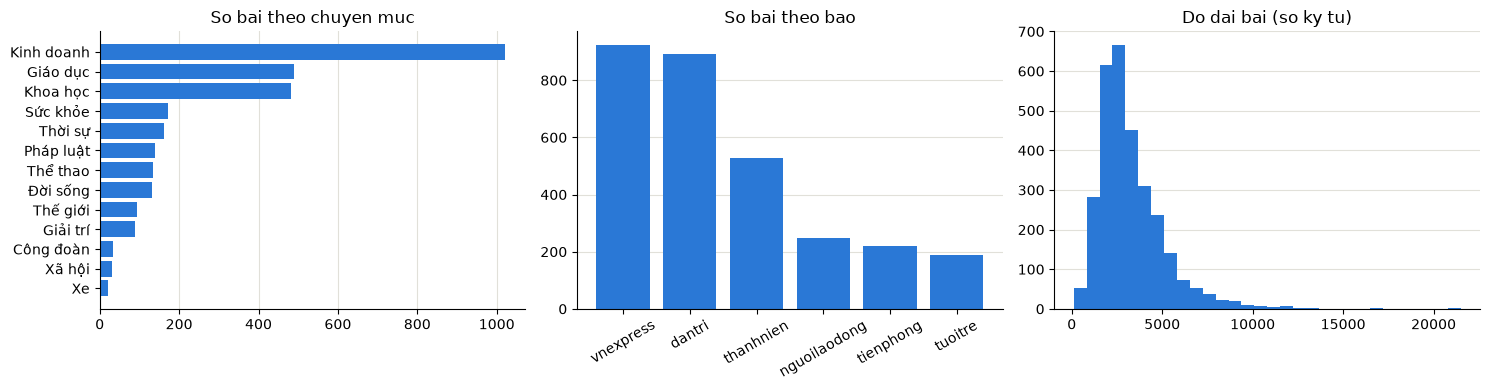

In [4]:
# bieu do mo ta du lieu: phan bo chuyen muc, phan bo bao, do dai bai
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cat_counts = df["category"].value_counts()
axes[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color=BLUE)
axes[0].set_title("So bai theo chuyen muc")
axes[0].grid(axis="x", color=GRID, linewidth=0.8)
axes[0].set_axisbelow(True)

src_counts = df["source"].value_counts()
axes[1].bar(src_counts.index, src_counts.values, color=BLUE)
axes[1].set_title("So bai theo bao")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", color=GRID, linewidth=0.8)
axes[1].set_axisbelow(True)

axes[2].hist(df["content"].str.len(), bins=30, color=BLUE)
axes[2].set_title("Do dai bai (so ky tu)")
axes[2].grid(axis="y", color=GRID, linewidth=0.8)
axes[2].set_axisbelow(True)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("output/data_overview.png", dpi=150)
plt.show()


**Giai doan 2 - Lam sach van ban**

In [5]:
def do_article_cleaning(txt):
    txt = re.sub(r"http[s]?://\S+", " ", txt)              # xoa URL
    txt = word_tokenize(txt, format="text")                 # tach tu tieng Viet
    out = txt.lower().split()                                # chu thuong
    out = [re.sub(r"[^\w]", "", w) for w in out]            # xoa dau cau, giu dau _
    out = [w for w in out if w and not re.search(r"\d", w)]  # bo token co so
    out = [w for w in out if w not in STOP_WORDS]            # bo stop words
    out = [w for w in out if len(w) >= 2]                     # bo token 1 ky tu
    return " ".join(out)


# vi du lam sach tren 1 bai mau
sample_raw = df["title"].iloc[0] + ". " + df["content"].iloc[0]
sample_clean = do_article_cleaning(sample_raw)
print("TRUOC:", sample_raw[:200])
print("SAU:  ", sample_clean[:200])


TRUOC: Lấy dị vật kim khâu nằm trong tầng sinh môn nữ bệnh nhân sau 11 năm. Một đoạn chiếc kim khâu nằm trong tầng sinh môn được lấy ra - Ảnh: T.G.

Ngày 28-1, Bệnh viện Hữu nghị Quảng Bình (phường Đồng Hới,
SAU:   dị_vật kim khâu nằm tầng sinh_môn nữ bệnh_nhân đoạn kim khâu nằm tầng sinh_môn ảnh tg bệnh_viện hữu_nghị quảng_bình phường đồng_hới quảng_trị phát_hiện xử_trí thành côngdị vậtlà kim khâu tồn_tại tầng 


In [6]:
# ghep tieu de + noi dung, lam sach toan bo, bo bai qua ngan
df["text"] = df["title"].fillna("") + ". " + df["content"].fillna("")
df["clean"] = df["text"].map(do_article_cleaning)
df = df[df["clean"].str.split().str.len() >= 20].reset_index(drop=True)

print("So bai sau lam sach:", len(df))
df.to_parquet("data/uvn_clean.parquet")  # luu lai, lan sau khong phai chay lai


So bai sau lam sach: 2993


**Giai doan 3 - Bag of Words**

In [7]:
clean_sentences = df["clean"].tolist()

# LDA can dem tho, khong dung TF-IDF
vectorizer = CountVectorizer(analyzer="word", max_df=0.5, min_df=5, max_features=2000)
clean_vec = vectorizer.fit_transform(clean_sentences)
feature_names = vectorizer.get_feature_names_out()

print(clean_vec.shape)


(2993, 2000)


**Giai doan 4 - Chon so chu de**

In [8]:
def perplexity_by_ntopic(data, ntopics, labels):
    rows = []
    for t in ntopics:
        lda_t = LatentDirichletAllocation(n_components=t, learning_method="online", random_state=RANDOM_STATE)
        lda_t.fit(data)
        pred = lda_t.transform(data).argmax(axis=1)
        rows.append({
            "Number Of Topics": t,
            "Perplexity Score": lda_t.perplexity(data),
            "NMI vs category": normalized_mutual_info_score(labels, pred),
        })
    return pandas.DataFrame(rows)


# grid search so chu de; NMI chi de tham khao, khong dung lam tieu chi chinh
df_perplexity = perplexity_by_ntopic(clean_vec, [5, 8, 10, 13, 15, 20], df["category"])
df_perplexity


,Number Of Topics,Perplexity Score,NMI vs category
0,5,851.226558,0.363375
1,8,784.822576,0.399857
2,10,728.209487,0.463125
3,13,715.987876,0.415534
4,15,688.882168,0.425979
5,20,675.416912,0.429767


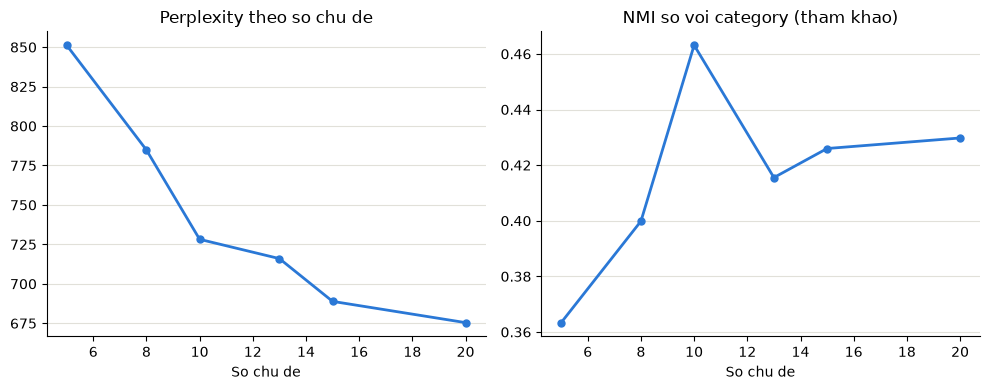

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(df_perplexity["Number Of Topics"], df_perplexity["Perplexity Score"],
             color=BLUE, marker="o", markersize=5, linewidth=2)
axes[0].set_title("Perplexity theo so chu de")
axes[0].set_xlabel("So chu de")

axes[1].plot(df_perplexity["Number Of Topics"], df_perplexity["NMI vs category"],
             color=BLUE, marker="o", markersize=5, linewidth=2)
axes[1].set_title("NMI so voi category (tham khao)")
axes[1].set_xlabel("So chu de")

for ax in axes:
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("output/perplexity.png", dpi=150)
plt.show()


**Giai doan 5 - Huan luyen LDA va doc ket qua**

In [10]:
def get_topics(mod, vec, names, docs, ndocs, nwords):
    W = mod.components_
    W_norm = W / W.sum(axis=1)[:, numpy.newaxis]  # ma tran tu x chu de, chuan hoa
    H = mod.transform(vec)                         # ma tran bai x chu de
    W_dict, H_dict = {}, {}
    for tpc in range(W.shape[0]):
        top_words = W_norm[tpc].argsort()[::-1][:nwords]
        W_dict[f"Topic {tpc}"] = [f"{names[i]} ({W_norm[tpc, i]:.3f})" for i in top_words]
        top_docs = H[:, tpc].argsort()[::-1][:ndocs]
        H_dict[f"Topic {tpc}"] = [f"{docs[i]} ({H[i, tpc]:.3f})" for i in top_docs]
    return pandas.DataFrame(W_dict), pandas.DataFrame(H_dict)


NUM_TOPICS = 10
lda = LatentDirichletAllocation(n_components=NUM_TOPICS, learning_method="online", random_state=RANDOM_STATE)
lda.fit(clean_vec)

W_df, H_df = get_topics(lda, clean_vec, feature_names, df["title"].tolist(), 10, 10)
W_df


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9
0,nghiên_cứu (0.016),y_tế (0.020),giá (0.034),xây_dựng (0.013),trận (0.030),đồng (0.050),công_an (0.019),trường (0.051),tết (0.014),phát_triển (0.023)
1,tàu (0.011),bệnh (0.019),usd (0.029),tổ_chức (0.013),đội (0.028),tỷ (0.037),cơ_quan (0.015),đại_học (0.030),ảnh (0.014),việt_nam (0.023)
2,điện (0.010),bệnh_viện (0.016),vàng (0.029),dự_án (0.012),giải (0.028),công_ty (0.031),quy_định (0.015),học (0.023),đi (0.013),doanh_nghiệp (0.021)
3,bay (0.010),bác_sĩ (0.012),mỹ (0.024),tỉnh (0.011),việt_nam (0.026),thuế (0.023),hàng (0.014),học_sinh (0.022),gia_đình (0.009),công_nghệ (0.021)
4,hệ_thống (0.010),virus (0.010),thị_trường (0.022),lao_động (0.011),cầu_thủ (0.020),ngân_hàng (0.019),vụ (0.014),thi (0.021),đường (0.009),kinh_tế (0.010)
5,khả_năng (0.008),điều_trị (0.009),đồng (0.017),đảng (0.011),đấu (0.016),triệu (0.017),vi_phạm (0.013),sinh_viên (0.019),xe (0.009),bền_vững (0.009)
6,hoạt_động (0.007),thuốc (0.009),triệu (0.015),phát_triển (0.009),vòng (0.014),vốn (0.016),hành_vi (0.013),giáo_dục (0.016),hàng (0.008),đầu_tư (0.008)
7,giúp (0.007),gia_đình (0.009),mua (0.012),nhà_nước (0.009),thi_đấu (0.013),tiền (0.016),tỉnh (0.012),ngành (0.014),khách_hàng (0.007),quốc_tế (0.008)
8,độ (0.007),phim (0.008),sản_phẩm (0.011),địa_phương (0.008),bóng_đá (0.013),cổ_phiếu (0.015),điều_tra (0.012),đào_tạo (0.012),triệu (0.006),chiến_lược (0.008)
9,năng_lượng (0.007),giúp (0.008),trung_quốc (0.010),quy_định (0.008),bóng (0.011),doanh_nghiệp (0.012),thông_tin (0.011),giáo_viên (0.011),thương_hiệu (0.006),hóa (0.007)


In [11]:
H_df


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9
0,Tàu vũ trụ Mỹ có thể bị đổ sau khi hạ cánh trê...,"Virus Nipah xuất hiện trở lại, Việt Nam siết c...","Vàng thế giới tụt dốc ở vùng đỉnh, các ""tay to...",Đại hội XIV: Bầu 180 Ủy viên Trung ương chính ...,Tương quan 4 cặp tứ kết nam Giải Bóng rổ Trẻ V...,"Ồ ạt báo lãi, tự doanh chứng khoán có dễ ‘kiếm...",Đặt mua pháo lậu trên Facebook đem về giấu dướ...,"Tuyển sinh ĐH 2026: Xét học bạ kèm điều kiện, ...",Ô mai Hồng Lam: Hương vị truyền thống kết nối ...,Doanh nghiệp đầu tư cho công nghệ để chiếm ưu ...
1,Nơi có thời tiết tồi tệ nhất thế giới (0.995),5 món giúp hạ đường huyết tự nhiên (0.995),Dự báo giá vàng sau tuần biến động mạnh mẽ (0....,"Điều động, bổ nhiệm hàng loạt cán bộ chủ chốt ...",Cầu Giấy đấu Vinschool The Harmony ở chung kết...,Lộ diện loạt doanh nghiệp lãi sau thuế tăng hơ...,Khởi tố thêm 1 phó giám đốc liên quan trung tâ...,Tuyển sinh ĐH 2026: Môn nào xuất hiện nhiều tr...,Nhà hàng Thanh Niên nói lời tạm biệt sau 36 nă...,"Ngày mai, báo Dân trí tổ chức Diễn đàn ESG Việ..."
2,Bắc Mỹ đang 'chảy giọt' vào lớp phủ Trái Đất (...,"Virus Nipah gây viêm não cấp, hệ số lây nhiễm ...",Dự báo giá vàng sau tuần tăng kỷ lục lên sát 5...,"Đà Nẵng xem xét giải thể 6 quỹ xã hội, từ thiệ...",THPT Phan Đình Phùng bị loại sớm tại Giải bóng...,Các doanh nghiệp bất động sản đua nhau báo lãi...,"Bắt nhóm thanh, thiếu niên trộm cắp tiền công ...",Tuyển sinh đại học 2026: Thí sinh chỉ được đăn...,Bí mật đằng sau sợi dây màu đỏ trên chậu hoa t...,"Hội thảo ""Thực thi ESG bằng khoa học công nghệ..."
3,Tàu đổ bộ tư nhân Mỹ 'chết' trên Mặt Trăng (0....,"Bộ Y tế khuyến cáo không ăn trái cây bị dơi, c...","Giá vàng miếng SJC lên mức 184,2 triệu đồng/lư...",Công bố quyết định của Ban Bí thư về công tác ...,Đình Bắc nhận Cúp 'Vua phá lưới' ngay trước tr...,Nhiều công ty chứng khoán lỗ đậm quý cuối năm ...,Xưởng nhựa trong khu dân cư bất ngờ bốc cháy d...,Vì sao loạt ngành ở ĐH Khoa học Xã hội và Nhân...,Mỗi năm hoa đào nở (0.976),Vì sao báo Dân trí tổ chức hội thảo thực thi E...
4,Tàu đổ bộ Mặt Trăng tư nhân Mỹ ngừng hoạt động...,"Virus Nipah: Nhanh trở nặng, dễ nhầm với cảm c...","Giá vàng trong nước, thế giới quay đầu giảm (0...",LĐLĐ TP HCM lý giải việc chậm cấp lại kinh phí...,"Nhận định Selangor vs CAHN, 20h00 ngày 28/1: N...","Prudential, Manulife, AIA… rót nghìn, chục ngh...",Nhóm trộm cắp tiền công đức liên tỉnh sa lưới ...,"Bỏ tổ hợp môn truyền thống, thí sinh có nhiều ...",Hộp bánh quy bơ lưu giữ ký ức Tết nhiều thế hệ...,Ngày mai diễn ra Diễn đàn ESG Việt Nam năm 202...
5,Lý do sao Hỏa có màu đỏ đặc trưng (0.995),"Virus Nipah nguy hiểm ra sao, cách phòng thế n...",Giá vàng rủ nhau giảm (0.996),Bí thư Thành ủy TPHCM Trần Lưu Quang chủ trì h...,Thủ môn ghi bàn phút cuối giúp Benfica hạ Real...,"Loạt công ty chứng khoán báo lãi đậm, lộ diện ...","Cháy xưởng nhựa tại xã Đông Thạnh, ảnh hưởng 8...",Đạt IELTS 5.5 'rộng cửa' vào lớp 10 trường tư ...,Thi ảnh Khát vọng năm rồng: Chợ hoa Bến Bình Đ...,"Dân trí tổ chức hội thảo ""Thực thi ESG bằng AI..."
6,Robot tự chế tạo cấu trúc mới tùy theo môi trư...,"Lần đầu tiên, bác sĩ Bệnh viện Nhi Đồng 1 chữa...","Vàng miếng SJC tăng lên mức 177,3 triệu đồng/l...",Tổng Bí thư dự Chương trình kỷ niệm 85 năm Ngà...,Vinschool The Harmony vô địch nam giải Bóng rổ...,"Lãi suất tiết kiệm tăng mạnh, gửi tiền ngân hà...",Hơn 2 tấn pháo lậu trên chiếc ô tô bán tải (0....,Dự kiến thí sinh chỉ có 10 nguyện vọng xét tuy...,Săn đặc sản ăn chơi ngày Tết - Kỳ 2: Cùng TikT...,"Doanh nghiệp không làm ESG thì mất cơ hội, làm..."
7,Bức ảnh đầu tiên của máy bay vũ trụ tuyệt mật ...,Tiểu đường ngày càng 'trẻ hóa': Nguyên nhân từ...,Giá vàng miếng SJC giảm gần 4 triệu đồng/lượng...,"Lấy ý kiến đoàn viên, người lao động về Dự thả...","Nhận định Barcelona vs Copenhagen, 03h00 ngày ...","Bùng nổ giao dịch, lợi nhuận công ty chứng kho...","Ập vào một căn nhà, công an phát hiện 32 con c...","Bộ GD&ĐT dự kiến siết phương thức tuyển sinh, ...",Ch

**Giai doan 6 - Truc quan hoa**

In [12]:
# bieu do tuong tac pyLDAvis, mo bang trinh duyet
import pyLDAvis
import pyLDAvis.lda_model

lda_plot = pyLDAvis.lda_model.prepare(lda, clean_vec, vectorizer, R=10, mds="tsne")
pyLDAvis.save_html(lda_plot, "output/lda_plot.html")
print("da luu output/lda_plot.html")


da luu output/lda_plot.html


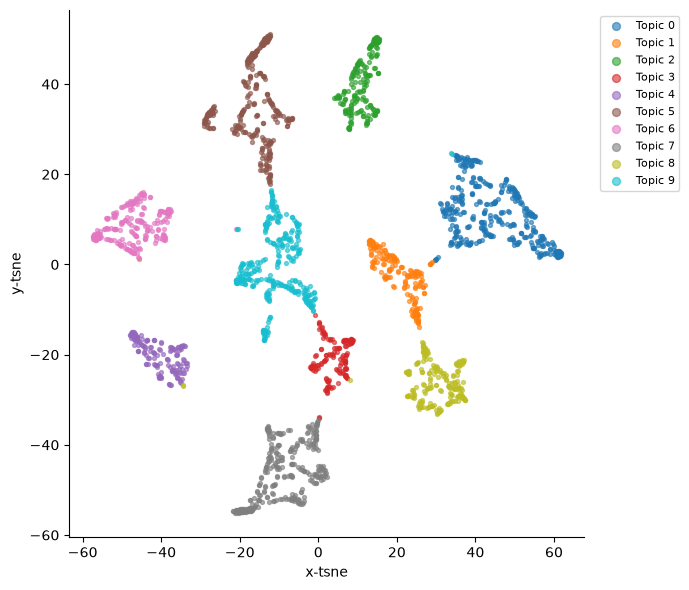

In [13]:
# t-SNE: giam chieu ma tran bai x chu de xuong 2D de ve
lda_transform = lda.transform(clean_vec)
dominant_topic = lda_transform.argmax(axis=1)
keep = lda_transform.max(axis=1) >= 0.5  # chi ve bai co chu de ro rang

tsne_fit = TSNE(n_components=2, random_state=RANDOM_STATE, init="pca").fit_transform(lda_transform[keep])
colors = plt.get_cmap("tab10")(numpy.linspace(0, 1, NUM_TOPICS))

fig, ax = plt.subplots(figsize=(7, 6))
for t in range(NUM_TOPICS):
    idx = dominant_topic[keep] == t
    ax.scatter(tsne_fit[idx, 0], tsne_fit[idx, 1], s=8, alpha=0.6, color=colors[t], label=f"Topic {t}")
ax.set_xlabel("x-tsne")
ax.set_ylabel("y-tsne")
ax.legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("output/tsne_lda.png", dpi=150)
plt.show()


**Giai doan 7 - Danh gia voi nhan category**

In [14]:
df["topic_lda"] = lda.transform(clean_vec).argmax(axis=1)

crosstab = pandas.crosstab(df["category"], df["topic_lda"])
crosstab


topic_lda,0,1,2,3,4,5,6,7,8,9
category,,,,,,,,,,
Công đoàn,0,1,0,18,0,2,5,1,5,2
Giáo dục,6,6,2,19,33,0,10,353,22,34
Giải trí,0,36,1,0,3,0,3,0,45,0
Khoa học,368,6,3,6,2,2,10,0,12,74
Kinh doanh,20,2,200,63,2,332,53,3,99,247
Pháp luật,1,4,3,6,0,1,118,3,1,2
Sức khỏe,0,147,4,4,0,0,9,0,3,5
Thế giới,27,7,34,5,0,0,10,2,4,6
Thể thao,1,1,2,0,123,1,0,0,4,1


In [15]:
print("NMI:", normalized_mutual_info_score(df["category"], df["topic_lda"]))
print("ARI:", adjusted_rand_score(df["category"], df["topic_lda"]))


NMI: 0.463125392709728
ARI: 0.34425712958250076


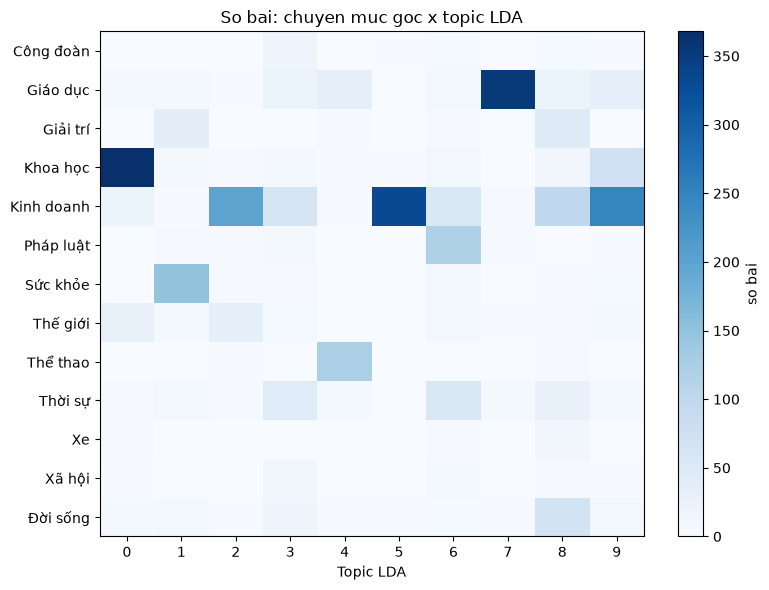

In [16]:
# heatmap: mau dam = nhieu bai, dung 1 hue (blue) cho du lieu magnitude
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(crosstab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(crosstab.shape[1]))
ax.set_xticklabels(crosstab.columns)
ax.set_yticks(range(crosstab.shape[0]))
ax.set_yticklabels(crosstab.index)
ax.set_xlabel("Topic LDA")
ax.set_title("So bai: chuyen muc goc x topic LDA")
fig.colorbar(im, ax=ax, label="so bai")
plt.tight_layout()
plt.savefig("output/crosstab_lda.png", dpi=150)
plt.show()
